# Which SME customers should an energy supplier fight to keep, and with what?
### A retention & pricing case for an energy retailer: churn, price, risk and uplift turned into one € decision

**The finding.** Spending a €10k retention budget on the customers *most likely to leave*, which is
what most retention teams do, returns almost nothing: **€0.7k net with a discount, €3.2k with an
account-manager call.** Spending the same €10k on the customers whose decision the offer can
actually *change*, and letting an optimiser pick which offer each one gets, returns
**€11.1k net, 3.5× more**, which is 83% of what perfect knowledge would achieve.

Three things make the difference, and each one is a lesson for the client:
1. **High churn risk is not the same as persuadable.** The riskiest customers are often lost causes.
2. **The average effect hides the real one.** The account-manager call cuts churn by ~9 points for
   multi-product customers and *raises* it by ~6 points for loyal customers we have never
   contacted. A plain A/B readout (+2.5 points on average) would miss both.
3. **The model is over-optimistic at the margin.** Its promised value keeps rising with budget,
   while the true value peaks around €10k. The analysis says how much to spend, not just on whom.

**Data:** 14,606 real SME energy customers (BCG PowerCo, public, CC0) with real 2015 tariffs and
real churn. The retention pilot is **simulated** on top of them, with effects I planted so every
estimate can be checked against a known truth. Every simulated element is labelled.

## 1. The question

An energy retailer sells gas and power to small businesses. About **1 in 10 leave every
quarter**. The commercial team has a retention budget and two levers:

| Offer | What it is | What it costs |
|---|---|---|
| **Discount** | 5% off the energy rate for 12 months | ~25% of that customer's annual margin, *paid by everyone who stays* |
| **Call** | a proactive account-manager call, no price change | ~€30 per call |

**The decision:** *for a given budget, which customers get which offer, and how much should we spend?*

It touches all four analytics domains in one chain, and each one feeds the next:

| Lens | Question | Method | Section |
|---|---|---|---|
| CLM / CRM | Who is likely to leave? | gradient boosting, calibrated, explained with SHAP | 3 |
| Risk | How many € are at risk, and where? | probability × margin | 4 |
| Revenue mgmt | Does price drive churn? | logistic regression, plus why it can't be trusted | 5 |
| Marketing | Whose decision does an offer change? | randomised pilot + uplift modelling | 6 |
| **Decision** | Who gets what, within budget? | integer optimisation | 7 |
| GenAI | Turn the list into briefs people act on | local LLM + deterministic fact-checker | 8 |

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

from src import (acquisition, features, propensity, risk, elasticity, simulate, uplift,
                 optimise, genai_briefs, factcheck, plots)
from src.config import DEFAULT_BUDGET_EUR, DISCOUNT_MARGIN_SHARE, CALL_COST_EUR

## 2. Data

**Real:** the BCG *PowerCo* dataset ([Kaggle, CC0](https://www.kaggle.com/datasets/erolmasimov/powerco)),
a European gas & power supplier's SME book: one row per customer (consumption, margins, tenure,
products, channel, contract dates, **churn in the next 3 months**) plus 12 months of 2015 tariffs
per customer. Channel and campaign codes are hashed in the source; I relabel them *Channel A, B…*.

`acquisition.load()` downloads it if needed and fails loudly if the schema has changed.

In [2]:
clients, prices = acquisition.load()
df = features.build(clients, prices)
df = df.join(features.business_segments(df))
print(f"{len(df):,} customers | churn rate {df['churn'].mean():.1%} | "
      f"annual net margin €{df['net_margin'].sum():,.0f} | {len(prices):,} monthly price rows")

14,606 customers | churn rate 9.7% | annual net margin €2,764,398 | 193,002 monthly price rows


**Leakage audit.** A model that sees the future looks great in testing and fails in production.
The snapshot is 1 Jan 2016, so every feature must be knowable on that date. The check below found
**61 customers with a product change dated after the snapshot**, and they churn more than average.
Using that field would leak the answer, so `features.build()` masks it for them.

In [3]:
features.leakage_audit(df)

,column,rows_after_snapshot,churn_rate_if_after,handling
0,date_activ,0,NaN,used (tenure)
1,date_modif_prod,61,0.115,future dates masked in build()
2,date_renewal,903,0.105,scheduled in advance; not used as a feature
3,date_end,14606,0.097,scheduled in advance; used as months_to_end


## 3. CLM lens: who is likely to leave?

Three models, all scored **out-of-fold** (each customer is scored by a model that never saw
them):
- a **logistic regression**, the simple benchmark. If it were as good, I would use it.
- a **gradient-boosted tree model** (LightGBM), which handles non-linear effects and interactions.
- the same GBM, **calibrated**. Later steps multiply probabilities by euros, so a "30%" must
  really mean 30%.

In [4]:
oof = propensity.out_of_fold(df)
df["p_churn"] = oof["p_gbm_cal"]
propensity.scorecard(df["churn"].to_numpy(), oof)

,AUC,avg_precision,brier,log_loss,mean_predicted,actual_rate
p_logit,0.646,0.168,0.086,0.308,0.097,0.097
p_gbm_raw,0.716,0.331,0.077,0.281,0.088,0.097
p_gbm_cal,0.715,0.327,0.077,0.280,0.097,0.097


**Reading it.** AUC measures ranking (0.5 = coin flip, 1 = perfect). The GBM ranks clearly better
than the logistic benchmark (0.72 vs 0.65), so the extra complexity earns its place. Calibration
barely changes ranking but fixes the **level**: the raw GBM predicts 8.9% churn on average against
9.7% actual. Under-predicting risk would understate the euros at risk by the same proportion.

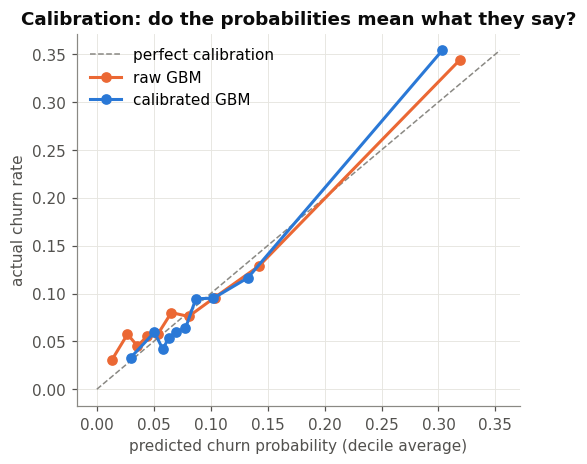

In [5]:
y = df["churn"].to_numpy()
plots.calibration(propensity.calibration_table(y, oof["p_gbm_raw"].to_numpy()),
                  propensity.calibration_table(y, oof["p_gbm_cal"].to_numpy()));

In [6]:
propensity.lift_table(y, df["p_churn"].to_numpy()).head(3)

,top_share,churn_rate,share_of_churners_reached,lift
0,0.100,0.354,0.364,3.645
1,0.200,0.235,0.484,2.421
2,0.300,0.189,0.582,1.941


The riskiest 10% of customers churn at **~35%, 3.6× the base rate**. That is a useful list, but
section 6 shows it is the wrong list to spend money on. (Why not a better churn model? Doubling the
features and a ~4× bigger model add only ~0.002 AUC, and the learning curve is flat: the limit is
information missing from the data, such as complaints, competitor offers and usage trends. The teaching
edition runs these tests.)

**Why is the model worried?** SHAP splits each prediction into the contribution of each feature.
Averaged over customers, it gives the global picture below. Per customer, it gives the "reasons"
the account manager sees in section 8.

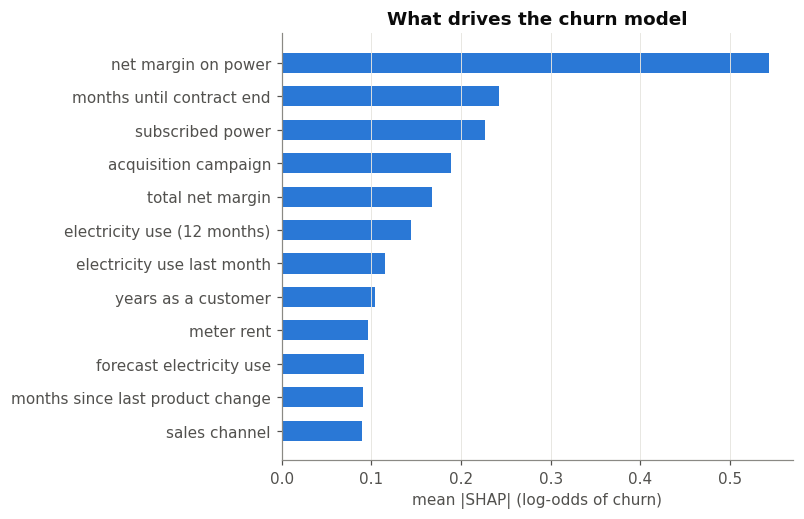

In [7]:
final_model = propensity.fit_final(df)
shap_all = propensity.shap_values(final_model, df[features.MODEL_FEATURES])
plots.shap_bar(shap_all, genai_briefs.FEATURE_LABELS);

Margin, time left on the contract, subscribed power and the acquisition campaign dominate. Price variables matter,
but less than the commercial team usually assumes, which leads to section 5. (SHAP explains the
*model*, not the world: "high margin pushes risk up" is an association, not a cause.)

## 4. Risk lens: how many euros are at risk?

`expected margin lost = P(churn) × annual net margin`. This is the number the CFO cares about,
and the reason calibration mattered.

In [8]:
risk.portfolio_summary(df).to_frame("value")

,value
customers,"14,606.000"
annual_net_margin_eur,"2,764,397.610"
expected_churners,"1,422.586"
margin_at_risk_eur,"293,839.607"
margin_at_risk_share,0.106


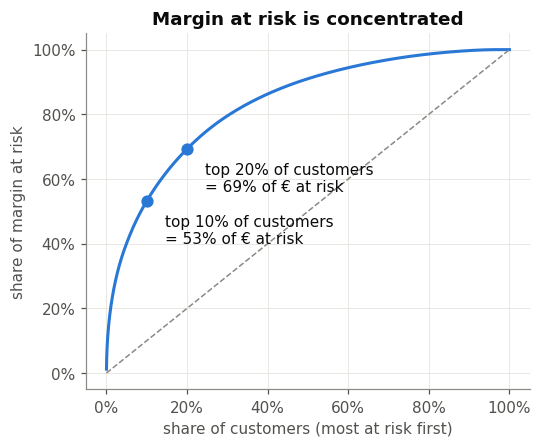

In [9]:
plots.concentration(risk.concentration(df));

About **€290k of €2.8M annual margin (~11%) is at risk**, and it is highly concentrated: the top
10% of customers hold over half of it. The top 1% by margin are **key accounts**, and those get a
named account manager rather than a campaign, so they are excluded from the targeting below
(`optimise.campaign_eligible`).

## 5. Revenue-management lens: does price drive churn?

The obvious RGM question: if we raise or cut prices, how does churn respond? Every customer's
energy price *fell* during 2015 (median −3.6%). Here is churn by size of the cut:

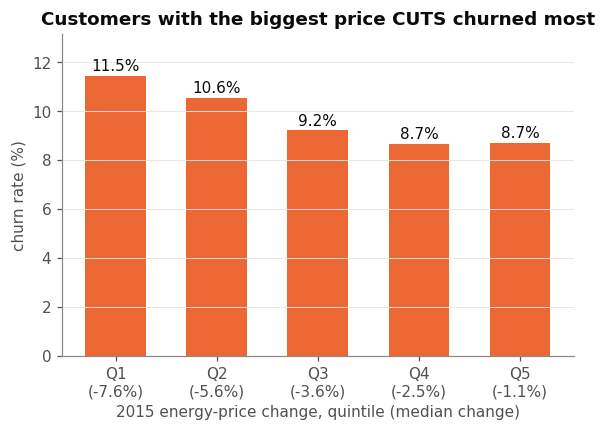

In [10]:
plots.churn_by_price_change(elasticity.churn_by_price_change(df));

Read naively: **the bigger the price cut, the more customers leave.** Nobody believes cutting
prices causes churn. The likely story is the reverse: the company cut prices for customers it
was already worried about. Price is *set in response to* churn risk. This is **confounding**, and
regression can't fix it. Watch the price coefficient as controls are added:

In [11]:
elasticity.price_effect_table(elasticity.fit_models(df))

,odds_ratio_per_1pct,or_ci95,pp_per_1pct,p_value,n
model,,,,,
naive,0.998,0.989 - 1.008,-0.014,0.732,14581
+ price level vs peers,1.006,0.996 - 1.017,0.056,0.239,14581
+ customer controls,1.008,0.998 - 1.018,0.068,0.135,14581


The effect is tiny, not significant, and changes direction with the specification. **The
observational data can't say whether a price offer keeps a customer.** The honest move is to
stop here and run an experiment, and that is what the next section does.

## 6. Marketing lens: whose decision can an offer change?

### The pilot (SIMULATED)
A random half of the book is split into three equal arms: no offer, discount, call. In a real
engagement this is a 6–8 week field test. Here it is simulated on the real customers
(`src/simulate.py`):
- each customer keeps their **real** churn outcome as the "no offer" outcome;
- a real churner who gets an offer is **persuaded to stay** with a probability I planted. Price-
  sensitive customers respond to the discount; relationship customers respond to the call;
- a call also **pushes some loyal, never-contacted customers to shop around** ("sleeping dogs").

Because the truth is planted, everything below can be **checked** against it.

In [12]:
pd.Series(simulate.PLANTED).to_frame("planted value")

,planted value
discount_base,0.100
discount_price_gap,0.500
discount_short_tenure,0.200
call_base,0.150
call_relationship,0.400
call_high_margin,0.200
call_sleeping_dog_rate,0.080
cap,0.750


In [13]:
po = simulate.run_pilot(df)
truth = simulate.true_effects(df, po)
ate = uplift.ate_table(po)
ate

,customers,churn_with_offer,churn_without,effect_pp,ci95_low_pp,ci95_high_pp,z
offer,,,,,,,
discount,2420,0.060,0.110,5.026,3.452,6.600,6.258
call,2395,0.086,0.110,2.458,0.773,4.143,2.859


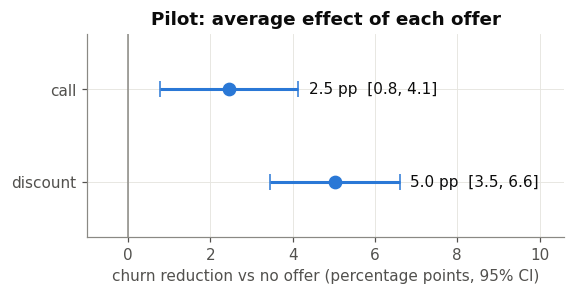

In [14]:
plots.pilot_effects(ate);

Both offers work **on average**, with confidence intervals clear of zero. A standard A/B readout
would stop here: "discount beats call, roll out the discount". That would be expensive,
because the average hides who the offers work for:

,relationship,offer,n_offer,n_control,effect_pp,ci95_pp
0,"loyal, single product, never changed",discount,462,468,2.060,3.300
1,"loyal, single product, never changed",call,464,468,-5.890,4.010
2,multi-product,discount,495,521,7.850,3.320
3,multi-product,call,525,521,8.850,3.180
4,other single product,discount,1463,1389,5.030,2.110
5,other single product,call,1406,1389,2.840,2.240


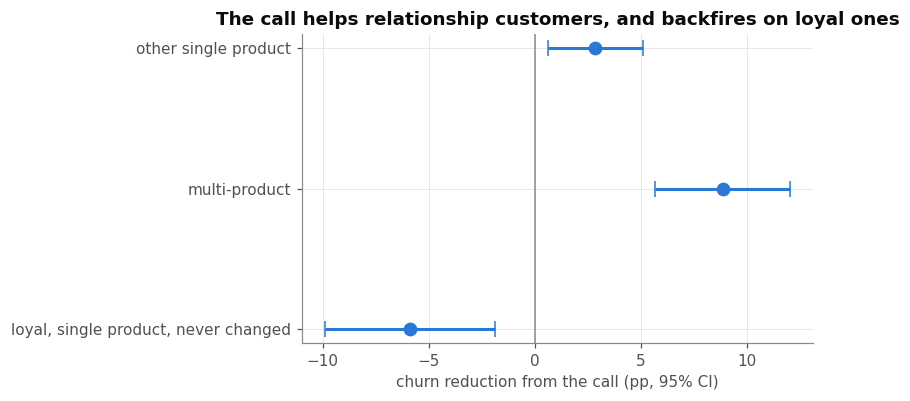

In [15]:
seg = uplift.segment_table(df, po, "relationship")
plots.segment_effects(seg, "relationship", "call",
                      "The call helps relationship customers, and backfires on loyal ones");
seg

The call cuts churn by **~9 points** for multi-product customers and **raises** it by **~6 points**
for loyal single-product customers who have never been contacted. Phoning them reminds them they
have a choice.

### Individual-level uplift
Segments are transparent but coarse. An **X-learner** estimates each customer's own effect: two
churn models (with and without the offer) give each pilot customer an *imputed* individual
effect, and a second model learns those effects from customer features. It is fitted on the pilot
only, then applied to the other half of the book.

In [16]:
tau_d = uplift.x_learner(df, po, "discount")
tau_c = uplift.x_learner(df, po, "call")
rollout = ~po["in_pilot"]
for offer, est in [("discount", tau_d), ("call", tau_c)]:
    r = np.corrcoef(est[rollout], truth.loc[rollout, f"tau_{offer}"])[0, 1]
    print(f"{offer:8s}: correlation between estimated and planted effect = {r:.2f}")

discount: correlation between estimated and planted effect = 0.67
call    : correlation between estimated and planted effect = 0.68


**Does it rank the right people first?** A Qini curve sorts customers by estimated effect and
counts how many are *actually saved* as we work down the list (the simulation knows the true
outcome under every offer). The comparison is the usual practice of ranking by churn risk.

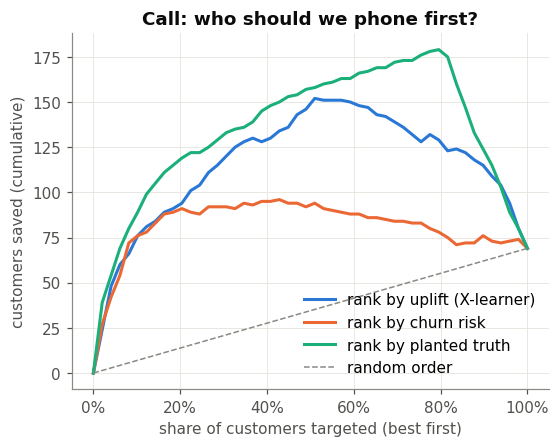

In [17]:
realised_call = (po["y_none"] - po["y_call"]).to_numpy()[rollout]
plots.qini({
    "rank by uplift (X-learner)": uplift.qini_curve(tau_c[rollout], realised_call),
    "rank by churn risk": uplift.qini_curve(df.loc[rollout, "p_churn"].to_numpy(), realised_call),
    "rank by planted truth": uplift.qini_curve(truth.loc[rollout, "tau_call"].to_numpy(), realised_call),
}, "Call: who should we phone first?");

For the **call**, ranking by uplift saves far more customers than ranking by risk, because risk
ranking phones sleeping dogs too. (For the discount, risk ranking does nearly as well, since that
effect is roughly proportional to risk. Uplift modelling isn't magic, and it matters most when
an action can backfire.)

## 7. The decision: who gets what, within budget?

For each eligible customer in the roll-out half and each offer:

`value = estimated drop in churn × annual margin − expected cost of the offer`

The discount's cost is paid by **everyone who stays**, including customers who would have
stayed anyway. That is why blanket discounts destroy margin. The optimiser then picks **at most
one offer per customer** to maximise total value within budget (a multiple-choice knapsack,
solved exactly with `scipy.optimize.milp`), and never picks an offer with negative expected value.

In [18]:
eligible = rollout & optimise.campaign_eligible(df)
R, P = df[eligible], po[eligible]
econ = optimise.offer_economics(R, tau_d[eligible], tau_c[eligible])
econ_true = optimise.offer_economics(R, truth.loc[eligible, "tau_discount"], truth.loc[eligible, "tau_call"])
budget = DEFAULT_BUDGET_EUR

policies = {
    "Riskiest first, discount": optimise.rank_and_fill(R["p_churn"], econ["spend_discount"], budget, "discount"),
    "Riskiest first, call": optimise.rank_and_fill(R["p_churn"], econ["spend_call"], budget, "call"),
    "Uplift + optimiser": optimise.solve(econ, budget),
    "Planted truth (ceiling)": optimise.solve(econ_true, budget),
}
comparison = pd.DataFrame({k: optimise.evaluate(v, R, P) for k, v in policies.items()}).T
comparison

,discounts,calls,customers_saved,sleeping_dogs_woken,spend_eur,margin_saved_eur,net_value_eur,roi
"Riskiest first, discount",319.000,0.000,48.204,0.000,"8,674.033","9,395.702",721.669,0.083
"Riskiest first, call",0.000,333.000,48.290,0.560,"9,990.000","13,176.096","3,186.096",0.319
Uplift + optimiser,43.000,311.000,52.412,0.000,"9,939.053","21,046.820","11,107.767",1.118
Planted truth (ceiling),64.000,293.000,62.894,0.000,"9,904.363","23,285.830","13,381.467",1.351


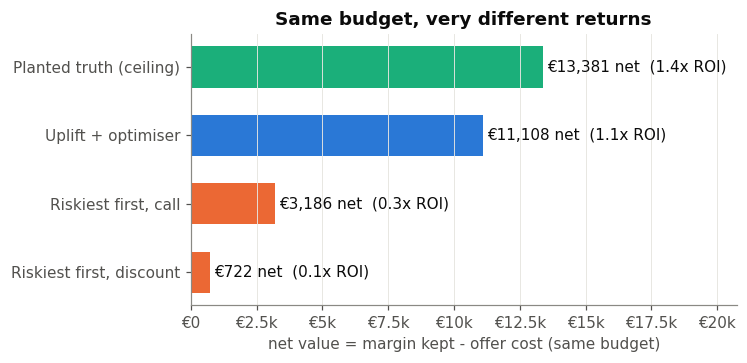

In [19]:
plots.policy_comparison(comparison);

**Same €10k, very different outcomes.** The riskiest-first lists spend the budget on lost causes
and sure things. The uplift + optimiser policy mostly phones relationship customers, gives a
discount only to a few high-risk, price-sensitive, high-margin customers, and leaves the sleeping
dogs alone.

### How much should we spend?

In [20]:
curve = optimise.budget_curve(econ, R, P, [1000, 2500, 5000, 7500, 10000, 15000, 20000, 30000])
plots.budget_curve(curve, chosen_budget=budget);
curve

,budget_eur,estimated_net_value_eur,true_net_value_eur,spend_eur,discounts,calls
0,1000,"4,308.961","3,189.318",998.612,5,33
1,2500,"7,926.021","7,476.989","2,512.585",6,82
2,5000,"11,786.882","9,440.560","5,058.967",18,162
3,7500,"14,416.773","10,801.426","7,538.496",31,238
4,10000,"16,273.583","11,107.767","9,939.053",43,311
5,15000,"18,635.730","10,980.785","14,699.531",93,436
6,20000,"19,852.228","8,969.917","19,390.634",140,554
7,30000,"20,105.078","6,324.044","22,971.135",181,639


The model's **promised** value keeps climbing; the **true** value peaks around €10k and then
falls. Past that point the optimiser is spending on customers whose estimated effect is mostly
noise. This is the *winner's curse*: picking the largest estimates also picks the largest
over-estimates. In practice I would recommend **€7.5–10k, plus a hold-out group to measure what
really happened**, and not the larger number the model suggests.

### ▶ Live: change the budget

In [21]:
BUDGET = 5_000   # <- change me and re-run

policy = optimise.solve(econ, BUDGET)
pd.DataFrame({
    "uplift + optimiser": optimise.evaluate(policy, R, P),
    "riskiest first, call": optimise.evaluate(
        optimise.rank_and_fill(R["p_churn"], econ["spend_call"], BUDGET, "call"), R, P),
}).T[["discounts", "calls", "customers_saved", "spend_eur", "net_value_eur", "roi"]]

,discounts,calls,customers_saved,spend_eur,net_value_eur,roi
uplift + optimiser,18.000,162.000,31.730,"5,058.967","9,440.560",1.866
"riskiest first, call",0.000,166.000,30.190,"4,980.000","3,479.337",0.699


## 8. GenAI: from a target list to briefs people act on

An account manager needs two sentences per customer, not a SHAP table. A small **open-weights
LLM (Qwen2.5-3B-Instruct, run locally, so no customer data leaves the machine)** drafted a brief
for 40 of the targeted customers (20 discount, 20 call), using two prompt styles:
- **open**: the facts in a friendly sentence plus "write a persuasive brief";
- **grounded**: a numbered fact sheet, explicit rules (only these numbers, only this offer), and a
  fixed output shape.

Generation ran once, offline (`python -m src.genai_briefs`). The text is loaded here as an input
dataset. **The checking below runs live**: plain Python and regular expressions with no LLM-as-judge,
so the checker can't hallucinate either.

,briefs,pass_rate,invented_number_rate,missing_offer_rate,unapproved_discount_rate,placeholder_rate,too_long_rate
condition,,,,,,,
grounded,40,0.950,0.050,0.000,0.000,0.000,0.000
open,40,0.175,0.050,0.050,0.000,0.725,0.250


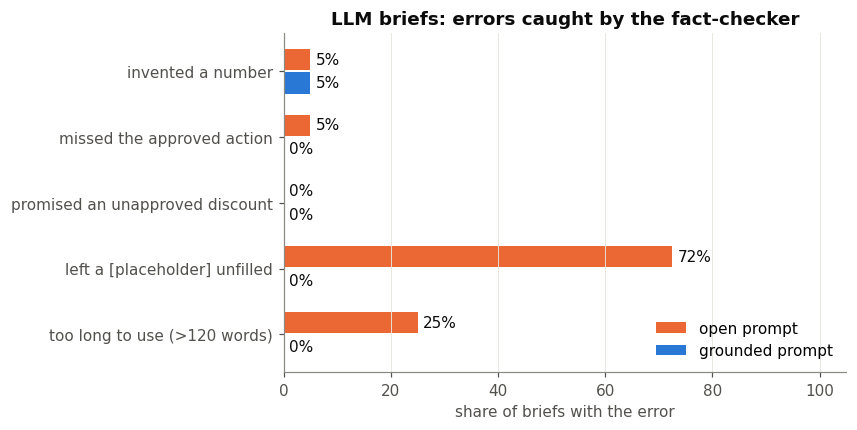

In [22]:
briefs = genai_briefs.load()
checked = factcheck.check_all(briefs)
summary = factcheck.summary(checked)
plots.factcheck_bars(summary);
summary

In [23]:
FLAGS = ["unsupported_numbers", "missing_recommended_offer", "unapproved_discount", "unfilled_placeholder", "too_long"]
example = checked[(checked["condition"] == "open") & (~checked["passes"])].iloc[0]
print("OPEN-PROMPT BRIEF:\n", example["text"][:900], "...")
print("\nFLAGGED:", {k: example[k] for k in FLAGS})
same = checked[(checked["condition"] == "grounded") & (checked["customer"] == example["customer"])].iloc[0]
print("\nGROUNDED BRIEF, same customer:\n", same["text"])
print("\nFLAGGED:", {k: same[k] for k in FLAGS})

OPEN-PROMPT BRIEF:
 Subject: Urgent Action Required: Retain Our Valuable Customer

Dear [Account Manager's Name],

I hope this message finds you well.

We have an urgent matter at hand that requires your immediate attention. Our valued customer with the account ID 24b06860 is currently facing a 69.1% risk of leaving our service. This customer not only brings in approximately EUR 239 annually but also represents a significant portion of our revenue and customer satisfaction.

To address this critical situation, we propose implementing a targeted retention strategy that includes offering a 5% discount on their energy rates for the next 12 months. This initiative will cost us about 25% of our margin, which we believe is a worthwhile investment to secure this valuable customer. ...

FLAGGED: {'unsupported_numbers': [], 'missing_recommended_offer': np.False_, 'unapproved_discount': np.False_, 'unfilled_placeholder': np.True_, 'too_long': np.False_}

GROUNDED BRIEF, same customer:
 Why at ri

And the hallucinations that got through grounding, which is why the checker exists:

In [24]:
for _, r in checked[(checked["condition"] == "grounded") & checked["has_unsupported_number"]].iterrows():
    print(f"invented {r['unsupported_numbers']} in:\n  {r['text']}\n")

invented [18.0] in:
  Why at risk: With a churn probability of 88.8%, this customer is highly at risk of leaving within the next three months.
Action: Offer a 5% off the energy rate for 12 months to retain them.
Worth it because: The expected net value of this offer is EUR 36, which represents about 18% of the annual net margin.

invented [15.2] in:
  Why at risk: The high churn probability (51.4%) indicates significant risk of losing the customer.
Action: Offer a 5% off the energy rate for 12 months.
Worth it because: The expected net value of the offer is EUR 22, which represents 15.2% of the annual net margin.



**What grounding fixed, and what it didn't.** The grounded prompt made **95% of briefs usable
as-is vs 18%** for the open prompt, which mostly wrote long letters with "[Account Manager's Name]"
placeholders. But **both styles invented a number in 1 brief in 20**. The grounded ones did it by
doing their own arithmetic ("about 18% of the annual margin"). Grounding improves behaviour; it does
not guarantee facts. That's why the deterministic check sits between the LLM and the account
manager: a failed brief is regenerated or goes to a human. The design trusts the LLM with
language and never with numbers or commitments.

## 9. Limitations

- **The pilot is simulated.** The planted effects are plausible but invented, so the € results
  show the *method* working against a known truth and are not a forecast of any real supplier's numbers. The
  first real step is a properly powered pilot.
- **The value of a saved customer is 12 months of margin.** That understates long-tenure
  customers; a lifetime-value model would change who is worth saving.
- **One churn window (3 months), one snapshot, one year of prices.** No seasonality, no
  competitor prices, no repeat-contact effects.
- **Uplift estimates are noisy** with ~2,400 customers per arm (the budget curve shows the cost).
  A larger pilot or shrinking estimates toward segment averages would help.
- **Optimisation treats the estimates as true.** A robust version would optimise a lower
  confidence bound of value, not the point estimate.
- **The fact-checker checks numbers, offers and format, not tone or whether the reasons are
  sensible.** It handles simple negation ("no discount needed" is not a promise) but not every
  phrasing. 40 briefs per prompt style is enough to see the pattern, not to quote error rates
  precisely.

## 10. Recommendation

1. **Stop ranking retention targets by churn risk alone.** Rank by *expected € saved net of offer cost*.
2. **Default to the call for multi-product customers; never phone loyal, untouched single-product
   customers.** Reserve the discount for the few high-risk, price-sensitive, high-margin customers.
3. **Spend ~€7.5–10k per quarter on this book, not more,** and keep a random hold-out so the true
   return is measured, not assumed.
4. **Run the real pilot first.** This notebook is the analysis plan for it: the same code runs
   unchanged on real pilot outcomes.

## Reproduce
```bash
python -m venv .venv && .venv/Scripts/pip install -r requirements.txt
.venv/Scripts/python -m pytest -q                      # 17 tests
.venv/Scripts/jupyter nbconvert --execute --to notebook --inplace notebooks/00_sme_energy_retention_final.ipynb
.venv/Scripts/python -m src.genai_briefs                 # optional: regenerate LLM briefs (GPU)
```